<a href="https://colab.research.google.com/github/Lorenzo-v8/Demanda-de-IA-en-Avisos-Laborales/blob/main/demanda_ia_avisos_laborales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Demanda de IA en Avisos Laborales
**Análisis exploratorio de datos sobre requisitos de IA en el mercado de empleo**
Autor: Lorenzo Ciprés

Este notebook analiza qué porcentaje de avisos laborales tech pide habilidades de IA, cruzando seis categorías de empleo, niveles de seniority y dos tipos de habilidad (IA generativa y Machine Learning clásico).

Objetivo adicional: **detectar y corregir quiebres metodológicos** en la propia serie (cambios abruptos en la cobertura de avisos relevados) antes de sacar conclusiones sobre la demanda real de IA.

**Fuente de datos:** [AI Requirements Index](https://www.datamatastudios.com/datasets/ai-requirements-index) de Datamata Studios, también publicado en [Kaggle](https://www.kaggle.com/datasets/datamatastudios/ai-requirements-index) y [Hugging Face](https://huggingface.co/datasets/datamatastudios/ai-requirements-index). Licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

## 0. Datos

Serie diaria con una fila por fecha × categoría × seniority × tier:

| columna | descripción |
|---|---|
| `snapshot_date` | fecha del relevamiento (UTC) |
| `category` | `data`, `engineering`, `product`, `devops`, `security`, `ai` |
| `seniority` | `all`, `entry`, `mid`, `senior`, `lead`, `unknown` |
| `tier` | `genai` (IA generativa), `ml` (ML clásico), `any_ai` (cualquiera de las dos) |
| `listings_with_ai` | avisos que mencionan al menos una habilidad del tier |
| `total_listings` | avisos activos relevados en ese grupo |
| `pct` | `listings_with_ai / total_listings × 100` |
| `required_count` | avisos donde la habilidad es requisito duro (puede venir vacío) |

Un aviso cuenta una sola vez por tier, sin importar cuántas habilidades de IA liste.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown

ROJO, GRIS = "#cc0000", "#4a4a4a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
         "septiembre", "octubre", "noviembre", "diciembre"]
NOMBRES = {"ai": "AI", "data": "Data", "engineering": "Engineering",
           "product": "Product", "security": "Security", "devops": "Devops"}

def es(x, d=1):
    """Formato numérico español: 1.234,5"""
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def fecha_es(f):
    return f"{f.day} de {MESES[f.month - 1]}"

def fechas(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_xlabel("Fecha")

In [2]:
# ============ CONFIGURACIÓN ============
URL_CSV = "https://www.datamatastudios.com/api/datasets/ai-requirements-index?format=csv"
RUTA_LOCAL = "ai-requirements-index.csv"   # alternativa: CSV descargado de Kaggle y subido a Colab
CATEGORIA_FOCO = "ai"                      # categoría que se analiza en detalle
FECHA_DESDE = None                         # ej: "2026-03-01"  (None = desde el inicio de la serie)
FECHA_HASTA = None                         # ej: "2026-07-22"  (None = hasta el último dato)
UMBRAL_SALTO = 1.8                         # un cambio de ×1,8 (o ÷1,8) en el universo se considera quiebre
# ========================================

try:
    df = pd.read_csv(URL_CSV, storage_options={"User-Agent": "Mozilla/5.0"})
    df.to_csv(RUTA_LOCAL, index=False)      # copia local para reproducibilidad
    print("Datos descargados de Datamata Studios y guardados en", RUTA_LOCAL)
except Exception as e:
    print("No se pudo descargar:", e)
    print("Usando copia local:", RUTA_LOCAL)
    df = pd.read_csv(RUTA_LOCAL)

df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])
for c in ["category", "seniority", "tier"]:
    df[c] = df[c].astype(str).str.lower().str.strip()
df = df.dropna(subset=["pct", "total_listings"])

if FECHA_DESDE: df = df[df["snapshot_date"] >= FECHA_DESDE]
if FECHA_HASTA: df = df[df["snapshot_date"] <= FECHA_HASTA]

ultima = df["snapshot_date"].max()
print(f"{len(df):,} registros · {df['snapshot_date'].nunique()} relevamientos "
      f"({df['snapshot_date'].min():%Y-%m-%d} → {ultima:%Y-%m-%d}) · {df['category'].nunique()} categorías")
df.head()

Datos descargados de Datamata Studios y guardados en ai-requirements-index.csv
7,437 registros · 105 relevamientos (2026-03-12 → 2026-11-19) · 6 categorías


,snapshot_date,category,seniority,tier,listings_with_ai,total_listings,pct,required_count
0,2026-03-12,ai,all,any_ai,253,266,95.1,253
1,2026-03-12,ai,all,genai,210,266,78.9,207
2,2026-03-12,ai,all,ml,186,266,69.9,186
3,2026-03-12,ai,entry,any_ai,1,1,100.0,1
4,2026-03-12,ai,entry,genai,1,1,100.0,1


In [3]:
# Serie principal: categoría foco, cualquier habilidad de IA, todos los niveles
foco = (df[(df["category"] == CATEGORIA_FOCO) & (df["tier"] == "any_ai") & (df["seniority"] == "all")]
        .sort_values("snapshot_date").set_index("snapshot_date"))
serie_pct = foco["pct"]
serie_tot = foco["total_listings"]
serie_ia = foco["listings_with_ai"]
nombre_foco = NOMBRES.get(CATEGORIA_FOCO, CATEGORIA_FOCO)

## 1. Un índice que parece moverse mucho
La lectura directa del dato puede ser contundente. Antes de aceptarla, conviene revisar qué hay detrás del porcentaje.

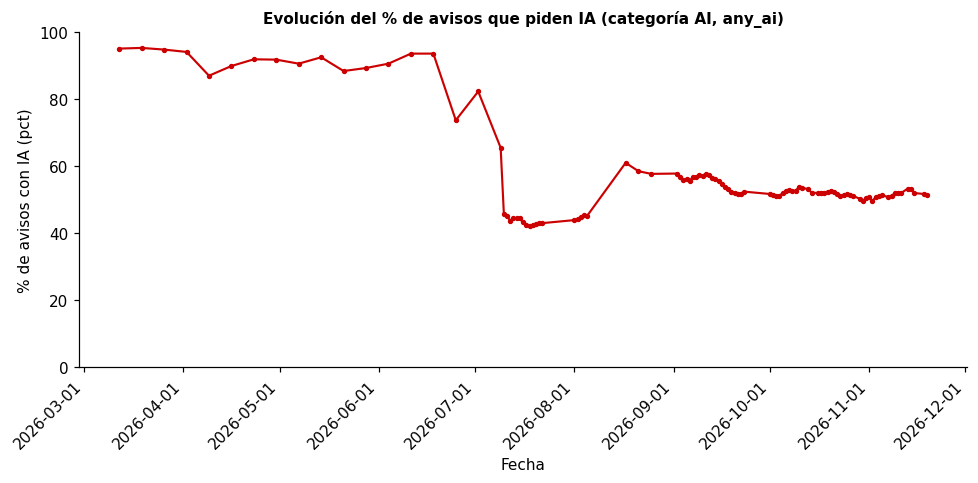

Lectura ingenua: 95,1% → 51,3%  (caída del 46%)


In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(serie_pct.index, serie_pct.values, color=ROJO, marker="o", ms=2.5, lw=1.4)
ax.set_ylim(0, 100)
ax.set_ylabel("% de avisos con IA (pct)")
ax.set_title(f"Evolución del % de avisos que piden IA (categoría {nombre_foco}, any_ai)", fontweight="bold", fontsize=10)
fechas(ax)
plt.tight_layout(); plt.show()

p0, p1 = serie_pct.iloc[0], serie_pct.iloc[-1]
var_ingenua = (p1 - p0) / p0 * 100
print(f"Lectura ingenua: {es(p0)}% → {es(p1)}%  ({'caída' if var_ingenua < 0 else 'suba'} del {es(abs(var_ingenua), 0)}%)")

## 2. Los quiebres metodológicos
Si el **universo total** de avisos relevados cambia abruptamente de un día para otro, el cambio es de alcance del relevamiento, no del mercado. Se detectan como saltos relativos del universo superiores a `UMBRAL_SALTO`.

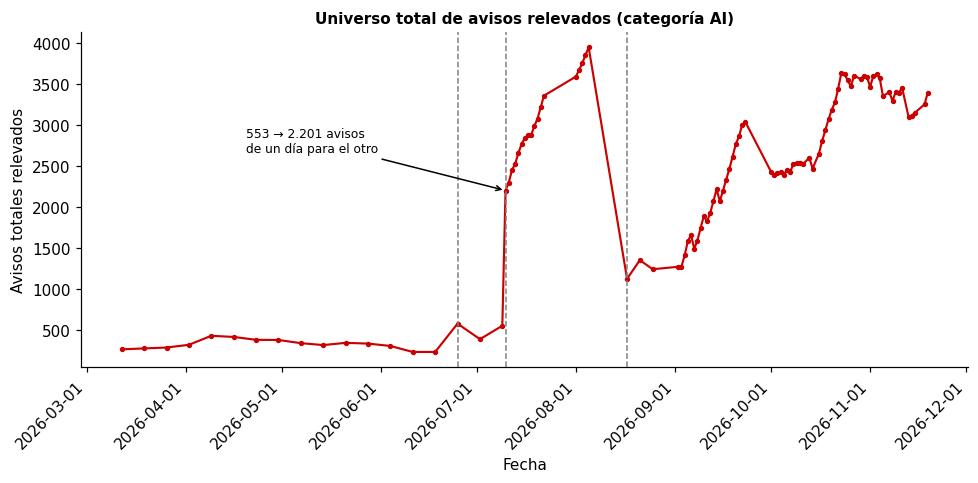

,universo_antes,universo_despues,factor,avisos_ia_antes,avisos_ia_despues
snapshot_date,,,,,
2026-06-25,234.0,579,2.47,219.0,427
2026-07-10,553.0,2201,3.98,362.0,1008
2026-08-17,3945.0,1125,0.29,1785.0,686


In [5]:
ratio = serie_tot / serie_tot.shift(1)
es_quiebre = (ratio >= UMBRAL_SALTO) | (ratio <= 1 / UMBRAL_SALTO)
quiebres = pd.DataFrame({
    "universo_antes": serie_tot.shift(1)[es_quiebre],
    "universo_despues": serie_tot[es_quiebre],
    "factor": ratio[es_quiebre],
    "avisos_ia_antes": serie_ia.shift(1)[es_quiebre],
    "avisos_ia_despues": serie_ia[es_quiebre],
})

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(serie_tot.index, serie_tot.values, color=ROJO, marker="o", ms=2.5, lw=1.4)
for f in quiebres.index:
    ax.axvline(f, color="gray", ls="--", lw=1)
if len(quiebres):
    f_max = np.log(quiebres["factor"]).abs().idxmax()      # el quiebre más grande
    q = quiebres.loc[f_max]
    ax.annotate(f"{es(q['universo_antes'], 0)} → {es(q['universo_despues'], 0)} avisos\nde un día para el otro",
                xy=(f_max, q["universo_despues"]), xytext=(-170, 25), textcoords="offset points",
                fontsize=8, arrowprops=dict(arrowstyle="->"))
ax.set_ylabel("Avisos totales relevados")
ax.set_title(f"Universo total de avisos relevados (categoría {nombre_foco})", fontweight="bold", fontsize=10)
fechas(ax)
plt.tight_layout(); plt.show()

if len(quiebres):
    out = quiebres.copy(); out.index = out.index.strftime("%Y-%m-%d")
    display(out.round(2))
else:
    print("No se detectaron quiebres con el umbral actual.")

## 3. La señal real, con el mismo criterio de medición
Se aísla el **tramo más largo con cobertura estable** (sin quiebres) y se mide ahí la variación.

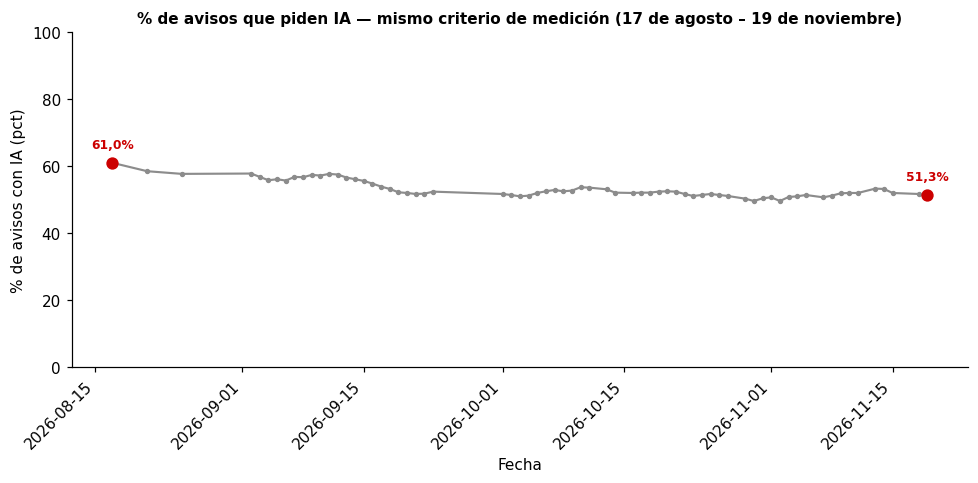

Tramo estable (68 relevamientos): 61,0% → 51,3%  (caída de 16% vs. 46% de la lectura ingenua)


In [6]:
segmento = es_quiebre.cumsum()                       # un id por tramo estable
id_estable = segmento.value_counts().idxmax()        # el tramo con más relevamientos
estable = serie_pct[segmento == id_estable]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(estable.index, estable.values, color="#8c8c8c", marker="o", ms=2.5, lw=1.4)
for x, y in [(estable.index[0], estable.iloc[0]), (estable.index[-1], estable.iloc[-1])]:
    ax.scatter([x], [y], color=ROJO, s=50, zorder=3)
    ax.annotate(f"{es(y)}%", (x, y), textcoords="offset points", xytext=(0, 10),
                color=ROJO, fontweight="bold", fontsize=8, ha="center")
ax.set_ylim(0, 100)
ax.set_ylabel("% de avisos con IA (pct)")
ax.set_title(f"% de avisos que piden IA — mismo criterio de medición ({fecha_es(estable.index[0])} – {fecha_es(estable.index[-1])})",
             fontweight="bold", fontsize=10)
fechas(ax)
plt.tight_layout(); plt.show()

e0, e1 = estable.iloc[0], estable.iloc[-1]
var_real = (e1 - e0) / e0 * 100
print(f"Tramo estable ({len(estable)} relevamientos): {es(e0)}% → {es(e1)}%  "
      f"({'caída' if var_real < 0 else 'suba'} de {es(abs(var_real), 0)}% vs. {es(abs(var_ingenua), 0)}% de la lectura ingenua)")

## 4. La IA se pide más cuanto más senior es el puesto
Promedio del % que pide IA (`any_ai`) por nivel de seniority, promediando las categorías, en el último relevamiento.

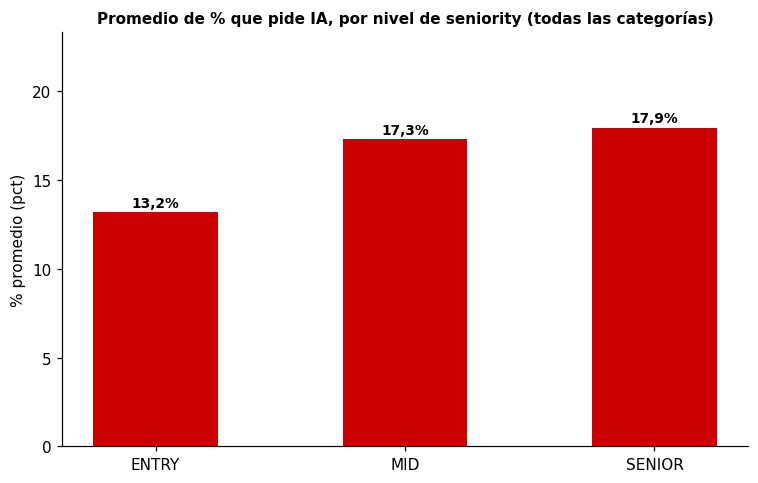

Senior vs. entrada: ×1,4


In [7]:
niveles = ["entry", "mid", "senior"]
u = df[df["snapshot_date"] == ultima]
sen = (u[(u["tier"] == "any_ai") & (u["seniority"].isin(niveles))]
       .groupby("seniority")["pct"].mean().reindex(niveles).dropna())

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar([s.upper() for s in sen.index], sen.values, color=ROJO, width=0.5)
for b, v in zip(barras, sen.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{es(v)}%", ha="center", fontweight="bold", fontsize=9)
ax.set_ylabel("% promedio (pct)")
ax.set_ylim(0, sen.max() * 1.3)
ax.set_title("Promedio de % que pide IA, por nivel de seniority (todas las categorías)", fontweight="bold", fontsize=10)
plt.tight_layout(); plt.show()

if {"entry", "senior"} <= set(sen.index):
    print(f"Senior vs. entrada: ×{es(sen['senior'] / sen['entry'], 1)}")

## 5. GenAI y ML no compiten por el mismo puesto
Brecha **GenAI − ML clásico** por categoría en el último relevamiento (puntos porcentuales).

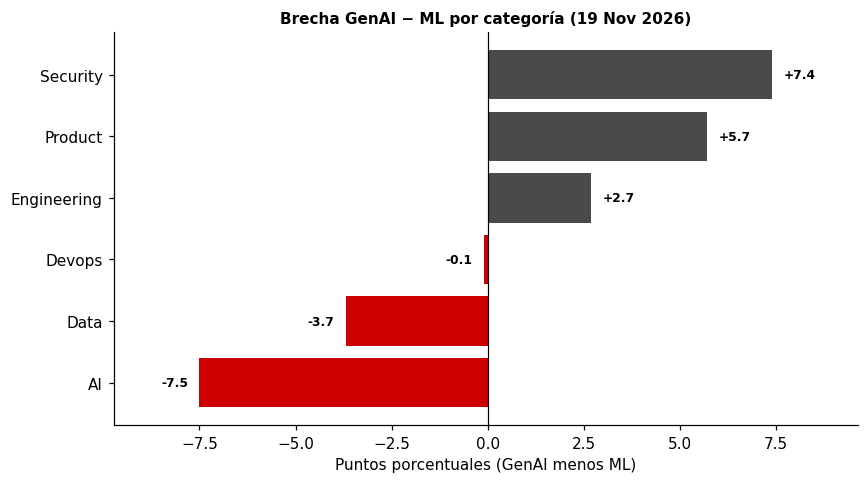

In [8]:
t = (u[(u["seniority"] == "all") & (u["tier"].isin(["genai", "ml"]))]
     .pivot(index="category", columns="tier", values="pct"))
brecha = (t["genai"] - t["ml"]).sort_values(ascending=False)
brecha.index = [NOMBRES.get(c, c) for c in brecha.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
cols = [GRIS if v > 0 else ROJO for v in brecha.values]
ax.barh(brecha.index[::-1], brecha.values[::-1], color=cols[::-1])
for y, v in zip(brecha.index[::-1], brecha.values[::-1]):
    ax.text(v + (0.3 if v > 0 else -0.3), y, f"{v:+.1f}", va="center",
            ha="left" if v > 0 else "right", fontweight="bold", fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Puntos porcentuales (GenAI menos ML)")
ax.set_title(f"Brecha GenAI − ML por categoría ({ultima:%d %b %Y})", fontweight="bold", fontsize=10)
ax.margins(x=0.15)
plt.tight_layout(); plt.show()

## Conclusiones

In [9]:
# --- cifras para las conclusiones ---
tot_ult = u[(u["tier"] == "any_ai") & (u["seniority"] == "all")].set_index("category")["total_listings"]
ratio_eng = tot_ult.get("engineering", np.nan) / tot_ult.get(CATEGORIA_FOCO, np.nan)

sen_foco = (u[(u["category"] == CATEGORIA_FOCO) & (u["tier"] == "any_ai")]
            .set_index("seniority")["pct"])

hacia_genai = [c for c, v in brecha.items() if v > 0]
hacia_ml = [c for c, v in brecha.items() if v < 0]

if len(quiebres):
    q_max = quiebres.loc[np.log(quiebres["factor"]).abs().idxmax()]
    f_q = np.log(quiebres["factor"]).abs().idxmax()
    verbo = f"multiplicó por **{es(q_max['factor'], 1)}**" if q_max["factor"] >= 1 else f"dividió por **{es(1 / q_max['factor'], 1)}**"
    txt_quiebre = (f"- Parte de la variación de **{es(abs(var_ingenua), 0)}%** en la lectura ingenua es un artefacto de medición: "
                   f"se detectaron **{len(quiebres)}** quiebre(s) del universo; el mayor fue el **{fecha_es(f_q)}**, cuando el universo se {verbo}.")
else:
    txt_quiebre = "- No se detectaron quiebres en el universo de avisos con el umbral actual."

lineas = [
    txt_quiebre,
    f"- Con criterio de medición constante (tramo estable del {fecha_es(estable.index[0])} al {fecha_es(estable.index[-1])}), "
    f"la exigencia de IA en la categoría {nombre_foco} pasó de **{es(e0)}%** a **{es(e1)}%** "
    f"({'caída' if var_real < 0 else 'suba'} de {es(abs(var_real), 0)}%).",
]
if {"entry", "senior"} <= set(sen.index):
    lineas.append(f"- La exigencia de IA escala con la seniority: los puestos senior la piden **{es(sen['senior'] / sen['entry'], 1)}x** "
                  f"más que los de nivel de entrada ({es(sen['entry'])}% vs. {es(sen['senior'])}% en promedio).")
lineas.append(f"- GenAI y ML se piden para funciones distintas: inclinan hacia GenAI **{', '.join(hacia_genai) or '—'}**; "
              f"hacia ML, **{', '.join(hacia_ml) or '—'}**.")
if not np.isnan(ratio_eng):
    lineas.append(f"- Ingeniería tiene **{es(ratio_eng, 1)}x** la cantidad de avisos de la categoría {nombre_foco}, "
                  f"pero exige IA en una fracción menor de los casos.")
if {"entry", "senior"} <= set(sen_foco.index):
    lineas.append(f"- Incluso dentro de la categoría {nombre_foco}, el nivel de entrada exige IA "
                  f"{'menos' if sen_foco['entry'] < sen_foco['senior'] else 'más'} que el senior "
                  f"(**{es(sen_foco['entry'], 0)}%** vs. **{es(sen_foco['senior'], 0)}%** en el último relevamiento).")

Markdown("\n".join(lineas) + """

*Fuente: Datamata Studios, AI Requirements Index (CC BY 4.0). Análisis realizado en Python (pandas + matplotlib) como proyecto de portfolio de ciencia de datos.*""")

- Parte de la variación de **46%** en la lectura ingenua es un artefacto de medición: se detectaron **3** quiebre(s) del universo; el mayor fue el **10 de julio**, cuando el universo se multiplicó por **4,0**.
- Con criterio de medición constante (tramo estable del 17 de agosto al 19 de noviembre), la exigencia de IA en la categoría AI pasó de **61,0%** a **51,3%** (caída de 16%).
- La exigencia de IA escala con la seniority: los puestos senior la piden **1,4x** más que los de nivel de entrada (13,2% vs. 17,9% en promedio).
- GenAI y ML se piden para funciones distintas: inclinan hacia GenAI **Security, Product, Engineering**; hacia ML, **Devops, Data, AI**.
- Ingeniería tiene **3,1x** la cantidad de avisos de la categoría AI, pero exige IA en una fracción menor de los casos.
- Incluso dentro de la categoría AI, el nivel de entrada exige IA menos que el senior (**42%** vs. **51%** en el último relevamiento).

*Fuente: Datamata Studios, AI Requirements Index (CC BY 4.0). Análisis realizado en Python (pandas + matplotlib) como proyecto de portfolio de ciencia de datos.*